In [1]:
%load_ext autoreload
%autoreload 2

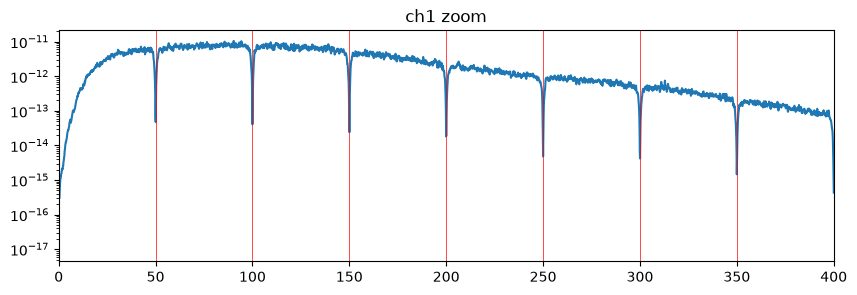

frequencies (Hz):      [ 30  50 100 200 300]
anti-alias delay (ms): [0.77 0.77 0.8  0.91 1.18]
high-pass delay (ms):  [6.06 2.05 0.48 0.13 0.07]


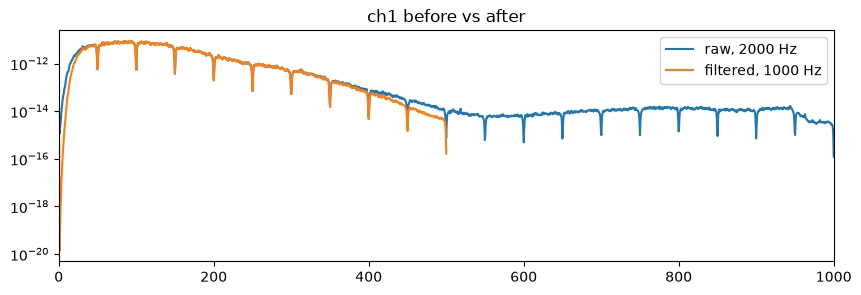

In [1]:
import numpy as np, scipy.io as sio, matplotlib.pyplot as plt
from scipy.signal import welch, butter, sosfilt, sos2tf, group_delay

d = sio.loadmat(r"D:\emg-project\data\raw\DB8\S1_E1_A1.mat")
emg = d["emg"].astype(np.float64)

# A. Zoom: do the downward dips sit exactly on multiples of 50 Hz?
f, P = welch(emg[:, 0], fs=2000, nperseg=16384)
plt.figure(figsize=(10, 3)); plt.semilogy(f, P)
for x in range(50, 401, 50): plt.axvline(x, color="r", lw=0.5)
plt.xlim(0, 400); plt.title("ch1 zoom"); plt.show()

# B. Design the two causal filters
aa = butter(4, 450, btype="lowpass",  fs=2000, output="sos")  # anti-aliasing before 2000 -> 1000 Hz
hp = butter(2, 20,  btype="highpass", fs=1000, output="sos")  # gentle drift removal

# C. How many ms does each filter delay the signal at typical EMG frequencies?
def delay_ms(sos, fs, freqs):
    b, a = sos2tf(sos)
    _, gd = group_delay((b, a), w=freqs, fs=fs)   # result is in samples
    return gd / fs * 1000
band = np.array([30, 50, 100, 200, 300])
print("frequencies (Hz):     ", band)
print("anti-alias delay (ms):", np.round(delay_ms(aa, 2000, band), 2))
print("high-pass delay (ms): ", np.round(delay_ms(hp, 1000, band), 2))

# D. Apply them causally (sosfilt, never filtfilt) and compare spectra
x = sosfilt(aa, emg, axis=0)[::2]     # filter, then keep every 2nd sample -> 1000 Hz
x = sosfilt(hp, x, axis=0)
f1, P1 = welch(emg[:, 0], fs=2000, nperseg=4096)
f2, P2 = welch(x[:, 0],   fs=1000, nperseg=2048)
plt.figure(figsize=(10, 3))
plt.semilogy(f1, P1, label="raw, 2000 Hz")
plt.semilogy(f2, P2, label="filtered, 1000 Hz")
plt.legend(); plt.xlim(0, 1000); plt.title("ch1 before vs after"); plt.show()